# NB6 · Transfer test: Tetouan, without re-tuning

Guide section "Generalisation to Tetouan", RQ5, Table 9. UCI Tetouan dataset: 3 distribution zones of one city, 2017, 10-min steps, power in kW (Salam & El Hibaoui 2018). The guide asks for three things:
1. the false-alarm rate on the real data;
2. recall on injected events;
3. the type distribution found.

**Frozen from the Morocco study** (nothing is chosen on Tetouan):
- every rule threshold, item and episode definition (rule engine v1);
- the **label model's parameters**, fitted on the Morocco votes and applied with `DawidSkene.predict` (one E-step, no refit);
- the detector architectures and training hyper-parameters (TCN-GAT main detector, its no-graph ablation, LightGBM);
- each detector's event formation (smoothing w, threshold percentile q, merge gap) from `dev_selection.json`;
- the injected signatures and the evaluation code (eq. 17).

**Re-estimated from Tetouan's own unlabelled data**, as the method prescribes for any new system:
- the expected value x̂ (eq. 1) and the robust-score scales;
- the predictor weights, trained on Tetouan's rule-clean steps and cross-fitted in two folds split at 1 Jul 2017;
- the threshold γ, as the frozen q-th percentile of Tetouan's own rule-negative zone-steps.

**Single-city limits** (D69):
- The city and region parts of the hierarchy coincide.
- The graph has only same-city edges.
- R1 (multi-city zero) and R7 (regional outage) cannot fire.
- G1 is the same event as G2 in one city, so it is not injected; multi-city types become city-wide.

**Evaluation:** 1 %, 3 % and 7 % × seeds 0–9 (30 injected datasets). Metrics over the whole year after the burn-in, since no Tetouan data is used for any choice.

**Runtime:** about 5 min for training plus about 1 min per dataset on CPU. Resumable. Decisions D68–D70.

In [1]:
import sys, subprocess, json, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm==4.6.0", "PyWavelets", "statsmodels", "openpyxl"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.stats import wilcoxon
import rules_v1 as R1, detector as D, benchmark as B, inject as INJ, graph_model as G, transfer as T
from viz import COL, LABEL_COL, savefig

RATES, SEEDS = [0.01, 0.03, 0.07], list(range(10))
TCN_CFG = dict(epochs=40, patience=6)            # as NB4
OUT = ROOT / "results" / "transfer_tetouan"; RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"
CSV = ROOT / "data" / "raw" / "tetouan" / "Tetuan City power consumption.csv"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
T.register()
SEL = json.loads((ROOT / "results" / "benchmark_v1" / "dev_selection.json").read_text())
print("main detector:", SEL["main"], "| device", G.default_device(), "| split", D.SPLIT.date())
T0 = time.time()

main detector: TCN-GAT, hierarchy, multi-scale | device cpu | split 2017-07-01


## 1. The Tetouan series

{'start': '2017-01-01 00:00:00', 'end': '2017-12-30 23:50:00', 'steps': 52416, 'duplicate_stamps': 0, 'missing_steps': 0, 'zeros': 0, 'longest_equal_run': 3}


,zone1,zone2,zone3
count,52416.0,52416.0,52416.0
mean,32345.0,21043.0,17835.0
std,7131.0,5201.0,6622.0
min,13896.0,8560.0,5935.0
25%,26311.0,16981.0,13129.0
50%,32266.0,20823.0,16415.0
75%,37309.0,24714.0,21624.0
max,52204.0,37409.0,47598.0


saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E22_tetouan_series.png


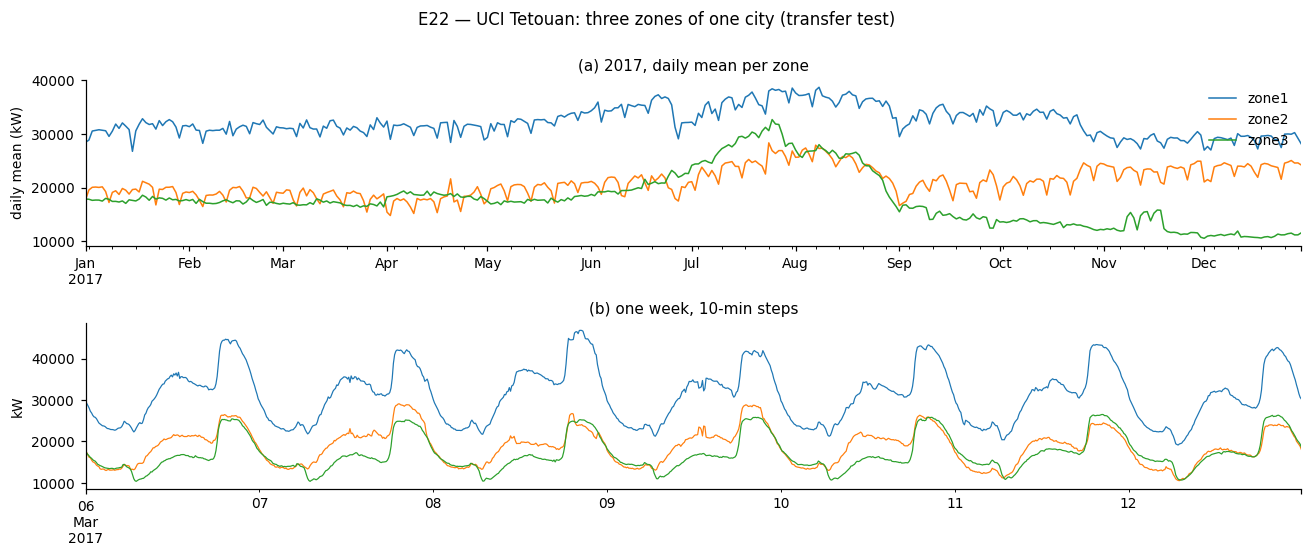

In [2]:
raw, data, weather = T.load(CSV)
x = data["Tetouan"]
st = raw["Tetouan"].DateTime
audit = dict(start=str(x.index[0]), end=str(x.index[-1]), steps=len(x), duplicate_stamps=int(st.duplicated().sum()),
             missing_steps=int(len(pd.date_range(st.min(), st.max(), freq="10min").difference(st))),
             zeros=int((x == 0).sum().sum()), longest_equal_run=int(max(x[c].groupby((x[c].diff() != 0).cumsum()).size().max() for c in x)))
print(audit)
display(x.describe().round(0))
fig, axs = plt.subplots(2, 1, figsize=(12, 5))
x.resample("1D").mean().plot(ax=axs[0], lw=1); axs[0].set_ylabel("daily mean (kW)"); axs[0].set_title("(a) 2017, daily mean per zone")
x.loc["2017-03-06":"2017-03-12"].plot(ax=axs[1], lw=.8, legend=False); axs[1].set_ylabel("kW"); axs[1].set_title("(b) one week, 10-min steps")
fig.suptitle("E22 — UCI Tetouan: three zones of one city (transfer test)", y=1.0); fig.tight_layout(); savefig(fig, FIG, "E22_tetouan_series"); plt.show()

## 2. Frozen rules and frozen label model on the real series (false alarms of the rules, type distribution)

In [3]:
ds, _ = T.frozen_label_model(ROOT / "data" / "raw" / "Data Morocco.xlsx")
tr = T.Transfer(raw, data, ds, SEL)
it = tr.real["items"]
print("items on the real Tetouan series:", it.kind.value_counts().to_dict(), "| zone runs:", len(tr.real["zr"]),
      "| rule outputs unseen in Morocco:", tr.real["unseen"])
display(it[["item_id", "kind", "start", "votes", "label", "confidence", "delta_star_min", "corr_best", "n_duplicate_stamps", "n_missing_steps"]])
it.to_csv(OUT / "real_items.csv", index=False)
print(f"clean region (where injection is allowed): {tr.clean.to_numpy().mean():.3f} of zone-steps")

items on the real Tetouan series: {'clock': 4} | zone runs: 0 | rule outputs unseen in Morocco: {}


,item_id,kind,start,votes,label,confidence,delta_star_min,corr_best,n_duplicate_stamps,n_missing_steps
0,K000,clock,2017-03-26,,N,0.968649,-10.0,0.9869,0,0
1,K001,clock,2017-05-21,,N,0.968649,10.0,0.9687,0,0
2,K002,clock,2017-07-02,,N,0.968649,-30.0,0.9621,0,0
3,K003,clock,2017-10-29,,N,0.968649,0.0,0.9901,0,0


clean region (where injection is allowed): 0.871 of zone-steps


## 3. Predictors trained on Tetouan (frozen hyper-parameters), and the detectors on the real series

In [4]:
tr.fit_predictors(TCN_CFG, G.default_device(), OUT / "models", log=False)
P = tr.P; pred = tr.predictions(P); ok = ~P["mask"] & P["rho"].notna()
mae = pd.DataFrame([dict(predictor=k, MAE=round(float((P["rho"] - v).abs()[ok].stack().mean()), 4)) for k, v in pred.items()])
mae.to_csv(OUT / "predictor_mae.csv", index=False); display(mae)
REAL = tr.analyse(data); tr.set_background(REAL)
months = (P["rho"].index[-1] - P["rho"].index[0]).days / 30.44
alarms = pd.DataFrame([dict(detector=k, w=tr.st[k]["w"], q=tr.st[k]["q"], gap=tr.st[k]["gap"], gamma=round(REAL["GAM"][k], 2),
                            real_alarms=len(d), per_zone_month=round(len(d) / (3 * months), 2),
                            alarm_zone_hours=round(float((d.duration_h * d.n_zones).sum()) if len(d) else 0.0, 1))
                       for k, d in REAL["DET"].items()])
alarms.to_csv(OUT / "real_alarms_by_detector.csv", index=False); display(alarms)
cal = D.calendar(P["rho"].index)
do = REAL["DET"][B.V_GAT].copy()
if len(do):
    pos = P["rho"].index.get_indexer(do.start)
    do["weekday"] = do.start.dt.day_name(); do["ramadan"] = cal.ramadan.to_numpy()[pos]; do["eid"] = cal.eid.to_numpy()[pos]
    do["holiday"] = cal.holiday.to_numpy()[pos]
    do.to_csv(OUT / "real_alarms_main_detector.csv", index=False)
    display(do[["start", "end", "zones", "duration_h", "max_score", "weekday", "ramadan", "eid", "holiday"]])

TCN-GAT loaded from C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\transfer_tetouan\models\tcn_gat.pt
TCN loaded from C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\transfer_tetouan\models\tcn.pt


,predictor,MAE
0,TCN-GAT,0.0447
1,TCN,0.0406
2,LGB,0.0110


,detector,w,q,gap,gamma,real_alarms,per_zone_month,alarm_zone_hours
0,"TCN-GAT, hierarchy, multi-scale",24,99.9,12,16.04,7,0.20,26.8
1,"TCN, no graph, hierarchy, multi-scale",24,99.9,12,14.12,9,0.25,25.7
2,"TCN, no graph, hierarchy, multi-scale (own tuned event f...",48,99.9,12,11.07,7,0.20,26.2
3,"LightGBM forecast, hierarchy, multi-scale",24,99.8,6,43.41,15,0.42,53.2
4,STL + MAD,24,99.8,12,8.20,13,0.36,48.7
5,Isolation Forest,3,99.5,3,0.68,72,2.01,136.8
6,LOF,24,99.8,12,2.06,11,0.31,130.3


,start,end,zones,duration_h,max_score,weekday,ramadan,eid,holiday
0,2017-04-20 10:30:00,2017-04-20 17:50:00,T1,7.333333,28.631519,Thursday,0,0,0
1,2017-04-20 13:00:00,2017-04-20 14:10:00,T2,1.166667,16.187078,Thursday,0,0,0
2,2017-07-04 09:50:00,2017-07-04 12:50:00,T1,3.000000,19.347556,Tuesday,0,0,0
3,2017-07-07 09:50:00,2017-07-07 13:20:00,T1,3.500000,23.030564,Friday,0,0,0
4,2017-09-28 04:10:00,2017-09-28 07:40:00,T3,3.500000,21.041415,Thursday,0,0,0
5,2017-11-12 07:20:00,2017-11-12 10:30:00,T3,3.166667,20.149073,Sunday,0,0,0
6,2017-11-20 09:20:00,2017-11-20 14:30:00,T3,5.166667,18.221587,Monday,0,0,0


## 4. Injection benchmark (resumable)
Observed Morocco signatures are injected into Tetouan's clean zone-time at 1 %, 3 % and 7 % (seeds 0–9). Types: A1 (city-wide exact zeros), A2, A3, G2 (city-wide noise floor), G3, G4, U_SHOCK (city-wide) and U_PARTIAL.

In [5]:
inj = INJ.Injector(data, tr.real["r"]["exp"], tr.clean, INJ.zone_map(data, [T.CITY], R1.CITY_SHORT))
todo = [(r, s) for r in RATES for s in SEEDS]
t_start = time.time(); done = 0
for rate, seed in todo:
    tag = f"r{int(round(rate * 100)):02d}_s{seed:02d}"
    if (RUNS / f"{tag}_detection.csv").exists():
        continue
    t = time.time()
    d_inj, truth = inj.sample(np.ones(len(tr.index), bool), rate, np.random.default_rng([int(round(rate * 1000)), seed]), types=T.TYPES_T)
    out = tr.analyse(d_inj, seed=seed)
    det, att = tr.metrics(out, truth)
    truth.to_csv(RUNS / f"{tag}_truth.csv", index=False)
    att.to_csv(RUNS / f"{tag}_attribution.csv", index=False)
    det.to_csv(RUNS / f"{tag}_detection.csv", index=False)
    done += 1
    left = sum(1 for r, s in todo if not (RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_detection.csv").exists())
    print(f"{tag}: {len(truth)} events, {time.time() - t:.0f} s | {left} left", flush=True)
print("all runs present:", all((RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_detection.csv").exists() for r, s in todo))

r01_s00: 33 events, 16 s | 29 left


r01_s01: 21 events, 15 s | 28 left


r01_s02: 30 events, 16 s | 27 left


r01_s03: 30 events, 15 s | 26 left


r01_s04: 25 events, 15 s | 25 left


r01_s05: 30 events, 16 s | 24 left


... (21 outputs left out)

r07_s07: 163 events, 55 s | 2 left


r07_s08: 189 events, 58 s | 1 left


r07_s09: 173 events, 57 s | 0 left


all runs present: True


## 5. Table 9: detection and attribution after transfer
Every alarm counts (primary). The own-background-excluded F1 removes each method's detections on the uninjected Tetouan series. Per-type recall is zone-strict.

In [6]:
def load(kind):
    return pd.concat([pd.read_csv(RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_{kind}.csv").assign(rate=r, seed=s) for r, s in todo], ignore_index=True)
DET, ATT, TRUTH = load("detection"), load("attribution"), load("truth")
print(len(todo), "datasets;", len(TRUTH), "injected events;", TRUTH.type.value_counts().to_dict())
def ms(x):
    x = pd.Series(x).dropna(); return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}" if len(x) > 1 else "n/a"
ORDER = ["ours (rules + detector)", "rules only (rule engine v1)"] + T.DETECTORS
rows = []
for rate in RATES:
    for m in ORDER:
        g = DET[(DET.rate == rate) & (DET.method == m)]
        rows.append(dict(rate=f"{rate:.0%}", method=m, F1=ms(g.f1), precision=ms(g.precision), recall=ms(g.recall), F1_zone_strict=ms(g.f1_zone),
                         F1_own_background_excluded=ms(g.f1_bgx), AUC_PR=ms(g.auc_pr), real_alarms=len(REAL["DET"].get(m, [])) if m in REAL["DET"] else np.nan))
table9 = pd.DataFrame(rows); table9.to_csv(OUT / "table9_detection.csv", index=False); display(table9)
wil = []
for rate in RATES:
    a = DET[(DET.rate == rate) & (DET.method == B.V_GAT)].set_index("seed").f1
    for m in ORDER:
        if m == B.V_GAT:
            continue
        b = DET[(DET.rate == rate) & (DET.method == m)].set_index("seed").f1.reindex(a.index)
        d = a - b
        wil.append(dict(rate=f"{rate:.0%}", comparison=f"main detector vs {m}", main=round(a.mean(), 4), other=round(b.mean(), 4),
                        main_wins=int((d > 0).sum()), p=float(wilcoxon(a, b).pvalue) if (d != 0).any() else 1.0))
wil = pd.DataFrame(wil); wil.to_csv(OUT / "table9_wilcoxon.csv", index=False); display(wil)
rec_cols = [f"recall_{t}" for t in T.TYPES_T]
rec = DET[DET.method.isin(["ours (rules + detector)", "rules only (rule engine v1)", B.V_GAT, B.V_TCN_MS, B.V_LGB])].groupby(["rate", "method"])[rec_cols].mean().round(3)
rec.to_csv(OUT / "table9_recall_by_type.csv"); display(rec)

30 datasets; 2778 injected events; {'A1': 418, 'A2': 342, 'G3': 340, 'U_SHOCK': 338, 'U_PARTIAL': 338, 'A3': 337, 'G2': 336, 'G4': 329}


,rate,method,F1,precision,recall,F1_zone_strict,F1_own_background_excluded,AUC_PR,real_alarms
0,1%,ours (rules + detector),0.945 ± 0.036,0.983 ± 0.055,0.913 ± 0.037,0.936 ± 0.039,0.952 ± 0.020,0.951 ± 0.018,NaN
1,1%,rules only (rule engine v1),0.856 ± 0.012,1.000 ± 0.000,0.749 ± 0.019,0.856 ± 0.012,0.856 ± 0.012,0.882 ± 0.038,NaN
2,1%,"TCN-GAT, hierarchy, multi-scale",0.857 ± 0.036,0.982 ± 0.057,0.763 ± 0.049,0.840 ± 0.040,0.860 ± 0.035,0.751 ± 0.088,7.0
3,1%,"TCN, no graph, hierarchy, multi-scale",0.832 ± 0.028,0.994 ± 0.018,0.717 ± 0.047,0.832 ± 0.028,0.826 ± 0.037,0.515 ± 0.100,9.0
4,1%,"TCN, no graph, hierarchy, multi-scale (own tuned event f...",0.799 ± 0.036,0.988 ± 0.024,0.672 ± 0.050,0.799 ± 0.036,0.795 ± 0.035,0.496 ± 0.109,7.0
5,1%,"LightGBM forecast, hierarchy, multi-scale",0.761 ± 0.059,0.746 ± 0.102,0.785 ± 0.050,0.753 ± 0.055,0.868 ± 0.042,0.839 ± 0.039,15.0
6,1%,STL + MAD,0.747 ± 0.039,0.774 ± 0.063,0.724 ± 0.038,0.747 ± 0.039,0.815 ± 0.033,0.800 ± 0.051,13.0
7,1%,Isolation Forest,0.483 ± 0.070,0.348 ± 0.072,0.812 ± 0.042,0.475 ± 0.056,0.820 ± 0.045,0.424 ± 0.087,72.0
8,1%,LOF,0.739 ± 0.060,0.755 ± 0.088,0.729 ± 0.050,0.739 ± 0.060,0.785 ± 0.059,0.660 ± 0.137,11.0
9,3%,ours (rules + detector),0.919 ± 0.008,1.000 ± 0.000,0.850 ± 0.013,0.908 ± 0.012,0.917 ± 0.006,0.954 ± 0.010,NaN


C:\Users\Dell\AppData\Roaming\Python\Python312\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\Dell\AppData\Roaming\Python\Python312\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Sample size too small for normal approximation.
  res = hypotest_fun_out(*samples, **kwds)


,rate,comparison,main,other,main_wins,p
0,1%,main detector vs ours (rules + detector),0.8570,0.9454,0,0.001953
1,1%,main detector vs rules only (rule engine v1),0.8570,0.8564,4,0.888638
2,1%,"main detector vs TCN, no graph, hierarchy, multi-scale",0.8570,0.8318,7,0.085831
3,1%,"main detector vs TCN, no graph, hierarchy, multi-scale (...",0.8570,0.7987,10,0.001953
4,1%,"main detector vs LightGBM forecast, hierarchy, multi-scale",0.8570,0.7606,10,0.001953
5,1%,main detector vs STL + MAD,0.8570,0.7467,10,0.001953
6,1%,main detector vs Isolation Forest,0.8570,0.4835,10,0.001953
7,1%,main detector vs LOF,0.8570,0.7393,9,0.003906
8,3%,main detector vs ours (rules + detector),0.7929,0.9189,0,0.001953
9,3%,main detector vs rules only (rule engine v1),0.7929,0.8607,0,0.001953


recall_A1  recall_A2  recall_A3  recall_G2  recall_G3  recall_G4  recall_U_SHOCK  recall_U_PARTIAL
rate method                                                                                                                                       
0.01 LightGBM forecast, hierarchy, multi-scale      1.000      0.863      0.350      1.000      0.950      0.975           0.200             0.900
     TCN, no graph, hierarchy, multi-scale          1.000      0.217      0.050      1.000      1.000      1.000           0.417             1.000
     TCN-GAT, hierarchy, multi-scale                1.000      0.628      0.058      1.000      0.975      1.000           0.308             0.975
     ours (rules + detector)                        1.000      1.000      1.000      1.000      1.000      1.000           0.308             0.975
     rules only (rule engine v1)                    1.000      1.000      1.000      0.950      1.000      1.000           0.000             0.000
0.03 LightGBM forecast, hierarchy, multi-scale      1.000      0.853      0.530      1.000      0.955      0.988           0.057             0.831
     TCN, no graph, hierarchy, multi-scale          1.000      0.287      0.012      1.000      0.978      0.962           0.069             0.761
     TCN-GAT, hierarchy, multi-scale                1.000      0.416      0.009      1.000      0.976      0.950           0.020             0.736
     ours (rules + detector)                        1.000      1.000      1.000      1.000      1.000      1.000           0.020             0.736
     rules only (rule engine v1)                    1.000      1.000      1.000      0.951      1.000      1.000           0.000             0.000
0.07 LightGBM forecast, hierarchy, multi-scale      0.934      0.628      0.193      0.841      0.879      0.889           0.005             0.446
     TCN, no graph, hierarchy, multi-scale          0.975      0.238      0.000      0.932      0.922      0.848           0.000             0.322
     TCN-GAT, hierarchy, multi-scale                0.935      0.323      0.000      0.873      0.937      0.912           0.000             0.340
     ours (rules + detector)                        1.000      1.000      1.000      0.987      1.000      1.000           0.000             0.340
     rules only (rule engine v1)                    0.997      1.000      1.000      0.919      1.000      1.000           0.000             0.000

In [7]:
att_rows = []
for (rate, seed), g in ATT.groupby(["rate", "seed"]):
    d = g[g.detected]
    att_rows.append(dict(rate=rate, seed=seed, detected_share=g.detected.mean(),
                         macro_F1_label_model=T.macro_f1(d.type, d.label), macro_F1_majority_vote=T.macro_f1(d.type, d.mv),
                         accuracy_label_model=(d.label == d.type).mean(), accuracy_majority_vote=(d.mv == d.type).mean(),
                         end_to_end=(g.label == g.type).mean()))
att_tab = pd.DataFrame(att_rows)
att_sum = att_tab.groupby("rate").agg(**{c: (c, ms) for c in att_tab.columns if c not in ("rate", "seed")})
att_sum.to_csv(OUT / "table9_attribution.csv"); display(att_sum)
r0 = 0.03; sub = ATT[(ATT.rate == r0) & ATT.detected]
cm = pd.crosstab(pd.Categorical(sub.type, categories=T.TYPED_T), pd.Categorical(sub.label, categories=T.TYPED_T + ["G1", "N"]), dropna=False)
cm.to_csv(OUT / "confusion_label_model_3pct.csv"); display(cm)
per_class = {c: round(float(((sub.type == c) & (sub.label == c)).sum() / max((sub.type == c).sum(), 1)), 3) for c in T.TYPED_T}
print("per-class accuracy (3 %):", per_class)

,detected_share,macro_F1_label_model,macro_F1_majority_vote,accuracy_label_model,accuracy_majority_vote,end_to_end
rate,,,,,,
0.01,0.992 ± 0.026,0.793 ± 0.064,0.793 ± 0.064,0.821 ± 0.062,0.821 ± 0.062,0.815 ± 0.070
0.03,0.992 ± 0.010,0.774 ± 0.050,0.781 ± 0.048,0.778 ± 0.044,0.781 ± 0.042,0.772 ± 0.044
0.07,0.986 ± 0.007,0.771 ± 0.018,0.785 ± 0.020,0.774 ± 0.018,0.780 ± 0.017,0.763 ± 0.018


col_0,A1,A2,A3,G2,G3,G4,G1,N
row_0,,,,,,,,
A1,18,0,0,90,2,0,0,0
A2,0,75,0,0,0,0,0,12
A3,0,0,86,0,0,0,0,0
G2,0,0,0,80,0,0,0,0
G3,0,0,0,0,72,13,0,0
G4,0,0,0,0,0,81,0,0


per-class accuracy (3 %): {'A1': 0.164, 'A2': 0.862, 'A3': 1.0, 'G2': 1.0, 'G3': 0.847, 'G4': 1.0}


## 6. Morocco vs Tetouan (same method, same settings)
Morocco: NB4 test period (Jul 2023 – May 2024, 15 zones, 3 cities). Tetouan: the whole of 2017 after the burn-in (3 zones, 1 city). The datasets differ, so this is context, not a paired test.

In [8]:
mor = pd.read_csv(ROOT / "results" / "benchmark_v1" / "table5_detection.csv")
mor6 = pd.read_csv(ROOT / "results" / "benchmark_v1" / "table6_attribution.csv")
cmp_rows = []
for rate in RATES:
    rs = f"{rate:.0%}"
    for m in ["ours (rules + detector)", "rules only (rule engine v1)", B.V_GAT, B.V_LGB, "STL + MAD"]:
        mo = mor[(mor.rate == rs) & (mor.method == m)]
        te = table9[(table9.rate == rs) & (table9.method == m)]
        cmp_rows.append(dict(rate=rs, method=m, Morocco_F1=mo.F1.iloc[0] if len(mo) else "n/a", Tetouan_F1=te.F1.iloc[0] if len(te) else "n/a"))
    mo = mor6[(mor6.rate == rs) & (mor6.labeler == "label model q")]
    cmp_rows.append(dict(rate=rs, method="attribution: label model macro-F1", Morocco_F1=mo.macro_F1.iloc[0] if len(mo) else "n/a",
                         Tetouan_F1=att_sum.loc[rate, "macro_F1_label_model"]))
cmp = pd.DataFrame(cmp_rows); cmp.to_csv(OUT / "morocco_vs_tetouan.csv", index=False); display(cmp)

,rate,method,Morocco_F1,Tetouan_F1
0,1%,ours (rules + detector),0.721 ± 0.047,0.945 ± 0.036
1,1%,rules only (rule engine v1),0.863 ± 0.032,0.856 ± 0.012
2,1%,"TCN-GAT, hierarchy, multi-scale",0.644 ± 0.067,0.857 ± 0.036
3,1%,"LightGBM forecast, hierarchy, multi-scale",0.623 ± 0.055,0.761 ± 0.059
4,1%,STL + MAD,0.625 ± 0.043,0.747 ± 0.039
5,1%,attribution: label model macro-F1,0.934 ± 0.055,0.793 ± 0.064
6,3%,ours (rules + detector),0.876 ± 0.008,0.919 ± 0.008
7,3%,rules only (rule engine v1),0.879 ± 0.013,0.861 ± 0.010
8,3%,"TCN-GAT, hierarchy, multi-scale",0.813 ± 0.020,0.793 ± 0.026
9,3%,"LightGBM forecast, hierarchy, multi-scale",0.765 ± 0.022,0.868 ± 0.020


## 7. Fig 13

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig13_tetouan.png


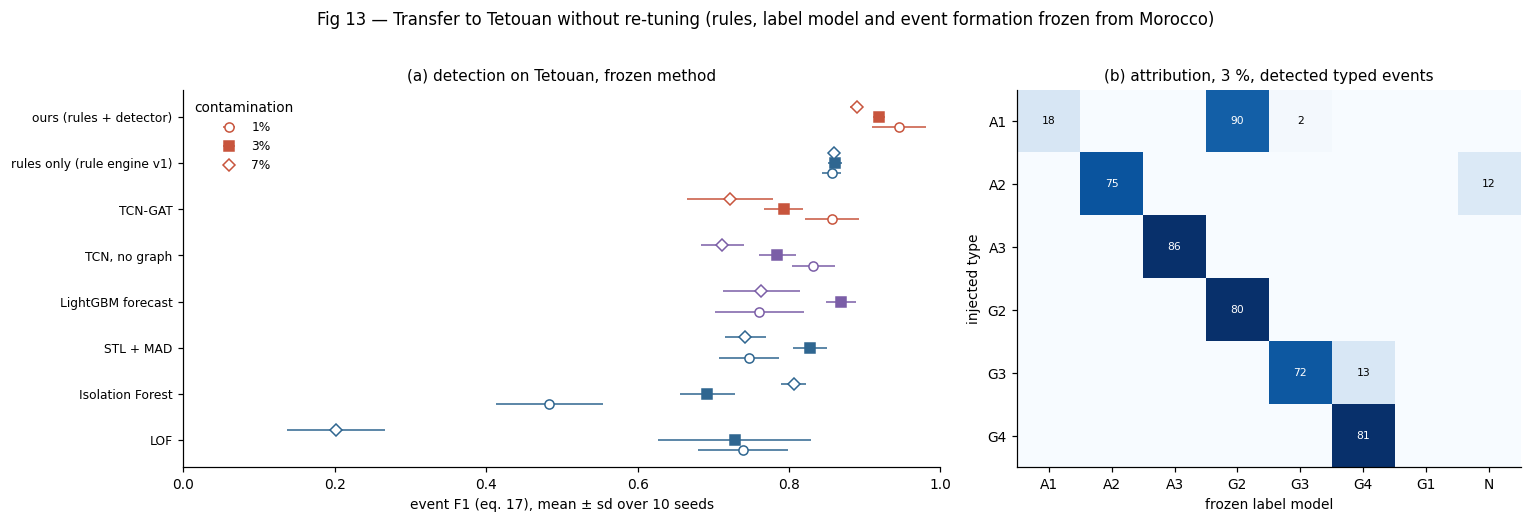

In [9]:
SHOW = ["ours (rules + detector)", "rules only (rule engine v1)", B.V_GAT, B.V_TCN_MS, B.V_LGB, "STL + MAD", "Isolation Forest", "LOF"]
COLM = {"ours (rules + detector)": "#C8553D", B.V_GAT: "#C8553D", "rules only (rule engine v1)": "#2F6690", "STL + MAD": "#2F6690",
        "Isolation Forest": "#2F6690", "LOF": "#2F6690", B.V_TCN_MS: "#7B5EA7", B.V_LGB: "#7B5EA7"}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.5, 1]))
ys = np.arange(len(SHOW))[::-1]
for k, (rate, mk) in enumerate(zip(RATES, ["o", "s", "D"])):
    for y, m in zip(ys, SHOW):
        g = DET[(DET.rate == rate) & (DET.method == m)].f1
        axs[0].errorbar(g.mean(), y + (k - 1) * 0.22, xerr=g.std(ddof=1), fmt=mk, color=COLM[m], ms=6, capsize=0, lw=1,
                        mfc=COLM[m] if rate == 0.03 else "white", label=f"{rate:.0%}" if y == ys[0] else None)
axs[0].set_yticks(ys); axs[0].set_yticklabels([m.replace(", hierarchy, multi-scale", "") for m in SHOW], fontsize=8)
axs[0].set_xlim(0, 1); axs[0].set_xlabel("event F1 (eq. 17), mean ± sd over 10 seeds"); axs[0].legend(title="contamination", fontsize=8)
axs[0].set_title("(a) detection on Tetouan, frozen method")
norm = cm.div(cm.sum(axis=1).replace(0, 1), axis=0)
axs[1].imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
axs[1].set_xticks(range(cm.shape[1])); axs[1].set_xticklabels(cm.columns); axs[1].set_yticks(range(cm.shape[0])); axs[1].set_yticklabels(cm.index)
for (i, j), v in np.ndenumerate(cm.values):
    if v: axs[1].text(j, i, v, ha="center", va="center", fontsize=7, color="w" if norm.values[i, j] > .6 else "k")
axs[1].set_xlabel("frozen label model"); axs[1].set_ylabel("injected type"); axs[1].set_title("(b) attribution, 3 %, detected typed events")
fig.suptitle("Fig 13 — Transfer to Tetouan without re-tuning (rules, label model and event formation frozen from Morocco)", y=1.02)
fig.tight_layout(); savefig(fig, FIG, "fig13_tetouan"); plt.show()

## 8. Summary

In [10]:
f1 = lambda m, r: round(float(DET[(DET.rate == r) & (DET.method == m)].f1.mean()), 3)
summary = dict(
    audit=audit, real_items=it.kind.value_counts().to_dict(), real_item_labels=it.label.value_counts().to_dict(),
    real_zone_runs=int(len(tr.real["zr"])), predictor_MAE=mae.set_index("predictor").MAE.to_dict(),
    real_alarms={r.detector: dict(n=r.real_alarms, per_zone_month=r.per_zone_month) for r in alarms.itertuples()},
    detection_F1={f"{r:.0%} | {m}": f1(m, r) for r in RATES for m in ORDER},
    detection_F1_bgx={f"{r:.0%} | {m}": round(float(DET[(DET.rate == r) & (DET.method == m)].f1_bgx.mean()), 3) for r in RATES for m in ORDER},
    recall={f"{r:.0%} | {m}": round(float(DET[(DET.rate == r) & (DET.method == m)].recall.mean()), 3) for r in RATES for m in ORDER},
    attribution={f"{r:.0%}": att_tab[att_tab.rate == r].drop(columns=["rate", "seed"]).mean().round(3).to_dict() for r in RATES},
    injected_events=int(len(TRUTH)), injected_by_type=TRUTH.type.value_counts().to_dict(), runtime_min=round((time.time() - T0) / 60, 1))
summary = json.loads(json.dumps(summary, default=float))
(OUT / "summary.json").write_text(json.dumps(summary, indent=2)); print(json.dumps(summary["detection_F1"], indent=1))

{
 "1% | ours (rules + detector)": 0.945,
 "1% | rules only (rule engine v1)": 0.856,
 "1% | TCN-GAT, hierarchy, multi-scale": 0.857,
 "1% | TCN, no graph, hierarchy, multi-scale": 0.832,
 "1% | TCN, no graph, hierarchy, multi-scale (own tuned event formation)": 0.799,
 "1% | LightGBM forecast, hierarchy, multi-scale": 0.761,
 "1% | STL + MAD": 0.747,
 "1% | Isolation Forest": 0.483,
 "1% | LOF": 0.739,
 "3% | ours (rules + detector)": 0.919,
 "3% | rules only (rule engine v1)": 0.861,
 "3% | TCN-GAT, hierarchy, multi-scale": 0.793,
 "3% | TCN, no graph, hierarchy, multi-scale": 0.785,
 "3% | TCN, no graph, hierarchy, multi-scale (own tuned event formation)": 0.759,
 "3% | LightGBM forecast, hierarchy, multi-scale": 0.868,
 "3% | STL + MAD": 0.828,
 "3% | Isolation Forest": 0.692,
 "3% | LOF": 0.728,
 "7% | ours (rules + detector)": 0.89,
 "7% | rules only (rule engine v1)": 0.86,
 "7% | TCN-GAT, hierarchy, multi-scale": 0.722,
 "7% | TCN, no graph, hierarchy, multi-scale": 0.712,
 "7%